In [1]:
if (!requireNamespace("mixOmics", quietly = TRUE)) {
    options(BioC_mirror = "https://bioconductor.org")
    BiocManager::install(version = "3.18", force = TRUE)
    BiocManager::install("mixOmics")
}

if (!requireNamespace("BiocParallel", quietly = TRUE)) {
    BiocManager::install("BiocParallel")
}

In [2]:
DATA_DIR <- "/home/mariya/Data/pallas"
DATA_DIR <- file.path(DATA_DIR, "mlomix_datasets/train-bimodal-reduced")
METH_FILE <- file.path(DATA_DIR, "features.dnam.csv")
GEX_FILE <- file.path(DATA_DIR, "features.gex.csv")
LABELS_FILE <- file.path(DATA_DIR, "labels.csv")

MIXOMICS_DIR <- "/home/mariya/Data/pallas/mixOmics"
COMP_NUM <- 35

In [3]:
source("helpers.R")
train_data <- data(GEX_FILE, METH_FILE, LABELS_FILE)

X_gex_train <- train_data$X_gex
X_dnam_train <- train_data$X_dnam
Y_train     <- train_data$Y

head(X_gex_train)
head(X_dnam_train)
head(Y_train)

Samples: 868 
GEX features: 199 
DNAm features: 6582 
Subtypes: AML, APL-PML::RARA AML, CBFA2T3::GLIS2 AML, CBFB::MYH11 AML, CEBPAalt AML, DEK::NUP214 AML, ETV6-r AML, FUS::ERG AML, KAT6A-r AML, KMT2A-r AML, NPM1alt AML, NUP98-r AML, PICALM::MLLT10 AML, RUNX1::RUNX1T1 B-ALL, BCR::ABL1 B-ALL, BCR::ABL1-like B-ALL, DUX4-r B-ALL, ETV6::RUNX1 B-ALL, ETV6::RUNX1-like B-ALL, high hyperdiploid B-ALL, iAMP21 B-ALL, KMT2A-r B-ALL, MEF2D-r B-ALL, PAX5 P80R B-ALL, PAX5alt B-ALL, TCF3::PBX1 B-ALL, ZNF384-r Non-leukemic T-ALL 


,ENSG00000079102,ENSG00000175505,ENSG00000185917,ENSG00000145113,ENSG00000102098,ENSG00000248329,ENSG00000164853,ENSG00000173825,ENSG00000073792,ENSG00000067177,⋯,ENSG00000164741,ENSG00000167528,ENSG00000114757,ENSG00000189325,ENSG00000132780,ENSG00000106004,ENSG00000175591,ENSG00000188269,ENSG00000142599,ENSG00000106665
ALL_1000,-1.596042,0.9493361,3.579807,-0.1403364,5.470482,13.046647,-1.596042,3.1679255,4.438548,1.2341500,⋯,-0.5086183,2.402686,-1.44748104,-1.596042,5.759100,3.593846,-0.3247489,-1.596042,7.283158,7.320186
ALL_1003,-1.596042,0.1570900,4.639638,-0.7255331,3.311799,-1.596042,-1.596042,0.8211017,3.970013,-1.2468383,⋯,-1.1032802,1.938077,-1.59604226,8.005105,7.045988,4.519395,-1.5960423,-1.596042,5.872816,8.132837
ALL_1005,-1.596042,-0.3729515,3.844026,2.0149281,5.150147,-1.596042,-1.596042,0.8482443,1.767218,-1.2297735,⋯,-1.4029350,3.076956,-1.59604226,-1.596042,7.105609,-1.596042,-1.5313228,-1.596042,4.940420,5.759756
ALL_1019,-1.596042,6.0413562,4.032419,-0.2970125,5.670480,-1.596042,-1.596042,4.0550008,2.290460,-1.2768282,⋯,-0.9616693,2.489532,-0.04867884,7.690148,6.713472,-1.596042,3.7400111,8.262904,5.732026,8.926576
ALL_1031,-1.596042,0.2815531,4.268223,2.4014250,5.320415,-1.596042,-1.596042,2.0749346,2.902432,-0.8894692,⋯,-1.4989847,2.631650,-1.59604226,-1.596042,6.975484,-1.596042,-1.5960423,-1.596042,5.378111,8.659184
ALL_1039,-1.596042,3.7105731,3.563106,5.9114389,4.290925,-1.596042,-1.596042,2.3230306,4.204582,-1.2207872,⋯,1.7752557,3.096701,-1.59604226,-1.280366,6.222201,-0.964650,4.8774092,-1.596042,6.025827,9.276772


,cg17259886,cg13293524,cg16288865,cg12923179,cg11622162,cg07232063,cg03763508,cg18638389,cg02707071,cg08166720,⋯,cg19557110,cg08911692,cg05807885,cg00527174,cg08473752,cg08870143,cg06814191,cg06710207,cg08523727,cg06671690
ALL_1000,0.9628,0.9734,0.2669,0.9124,0.0519,0.8871,0.9589,0.9350,0.9530,0.9419,⋯,0.9679,0.9551,0.0817,0.0413,0.9560,0.9348,0.9375,0.9353,0.1773,0.3090
ALL_1003,0.9543,0.9784,0.9405,0.9111,0.0512,0.9138,0.9501,0.9287,0.9587,0.9059,⋯,0.9557,0.9493,0.0343,0.1358,0.9543,0.9377,0.9402,0.9389,0.8985,0.0131
ALL_1005,0.9567,0.9688,0.9195,0.9326,0.0571,0.9326,0.8014,0.9232,0.9447,0.9334,⋯,0.9486,0.9413,0.5024,0.0513,0.9357,0.9436,0.9134,0.9285,0.5752,0.2365
ALL_1019,0.9406,0.9741,0.9442,0.9032,0.0394,0.6195,0.9358,0.9481,0.9608,0.4691,⋯,0.9561,0.9526,0.0308,0.1097,0.9293,0.9478,0.9392,0.8979,0.9337,0.0127
ALL_1031,0.9483,0.9751,0.9297,0.9276,0.0503,0.8530,0.9576,0.9438,0.9563,0.9559,⋯,0.9623,0.9613,0.3448,0.0494,0.9553,0.6602,0.9439,0.9418,0.9432,0.0560
ALL_1039,0.9539,0.9782,0.9439,0.9222,0.0484,0.9325,0.9549,0.9351,0.9427,0.9470,⋯,0.9541,0.9524,0.1041,0.0670,0.9273,0.6549,0.8594,0.9298,0.9235,0.0121


[1] B-ALL, DUX4-r         B-ALL, PAX5alt        B-ALL, MEF2D-r       
[4] B-ALL, ZNF384-r       B-ALL, BCR::ABL1-like B-ALL, BCR::ABL1     
28 Levels: AML, APL-PML::RARA AML, CBFA2T3::GLIS2 ... T-ALL

In [4]:
library(mixOmics)
library(caret)
library(BiocParallel)

Loading required package: MASS

Loading required package: lattice

Loading required package: ggplot2


Loaded mixOmics 6.26.0
Thank you for using mixOmics!
Tutorials: http://mixomics.org
Bookdown vignette: https://mixomicsteam.github.io/Bookdown
Questions, issues: Follow the prompts at http://mixomics.org/contact-us
Cite us:  citation('mixOmics')



Attaching package: ‘caret’


The following objects are masked from ‘package:mixOmics’:

    nearZeroVar, plsda, splsda




In [5]:
gex_perf <- readRDS(file.path(MIXOMICS_DIR, "gex_perf.rds"))
dnam_perf <- readRDS(file.path(MIXOMICS_DIR, "dnam_perf.rds"))
diablo_perf <- readRDS(file.path(MIXOMICS_DIR, "diablo_perf.rds"))

In [6]:
comp_num <- COMP_NUM

gex_ber    <- gex_perf$error.rate.class$max.dist[, paste0("comp", comp_num)]
dnam_ber   <- dnam_perf$error.rate.class$max.dist[, paste0("comp", comp_num)]
diablo_ber <- rowMeans(cbind(
  diablo_perf$error.rate.per.class$GEX$max.dist[,  paste0("comp", comp_num)],
  diablo_perf$error.rate.per.class$DNAm$max.dist[, paste0("comp", comp_num)]
))

In [7]:
library(ggplot2)
library(tidyr)
library(dplyr)
library(ggrepel)

# ============================================================
# Convert to balanced accuracy
# ============================================================
bacc_df <- data.frame(
  Class  = names(gex_ber),
  GEX    = 1 - as.numeric(gex_ber),
  DNAm   = 1 - as.numeric(dnam_ber),
  DIABLO = 1 - as.numeric(diablo_ber)
)

bacc_long <- pivot_longer(bacc_df, cols = c("GEX","DNAm","DIABLO"),
                          names_to = "Model", values_to = "BalAcc")



Attaching package: ‘dplyr’


The following object is masked from ‘package:MASS’:

    select


The following objects are masked from ‘package:stats’:

    filter, lag


The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union




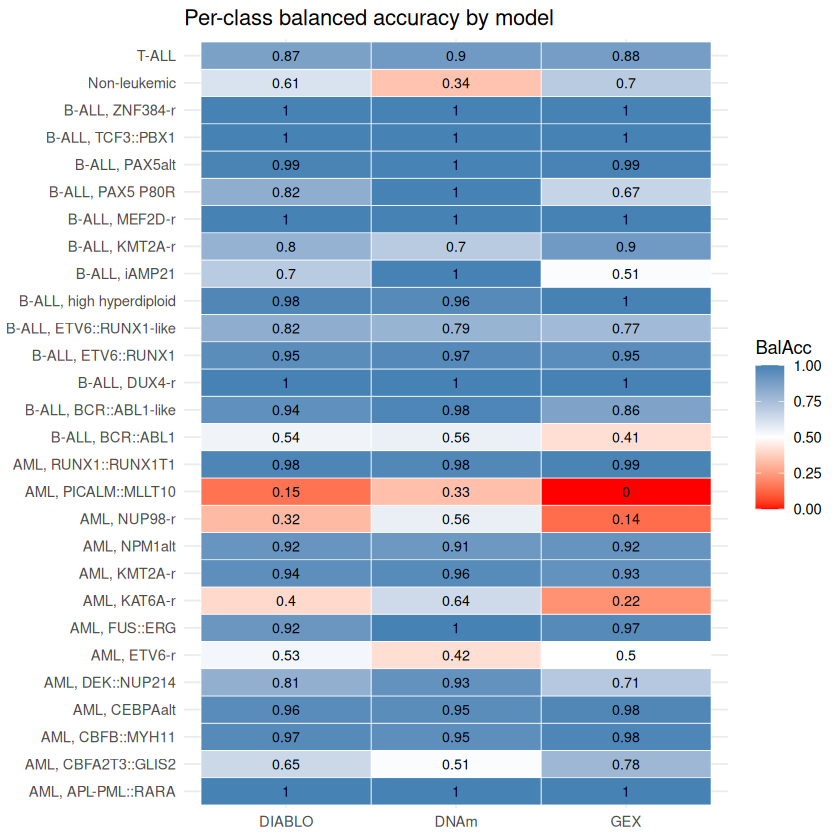

In [8]:

# ============================================================
# 1. Heatmap
# ============================================================
ggplot(bacc_long, aes(x = Model, y = Class, fill = BalAcc)) +
  geom_tile(colour = "white") +
  scale_fill_gradient2(low = "red", mid = "white", high = "steelblue",
                       midpoint = 0.5, limits = c(0, 1)) +
  geom_text(aes(label = round(BalAcc, 2)), size = 3) +
  labs(title = "Per-class balanced accuracy by model", x = NULL, y = NULL) +
  theme_minimal()


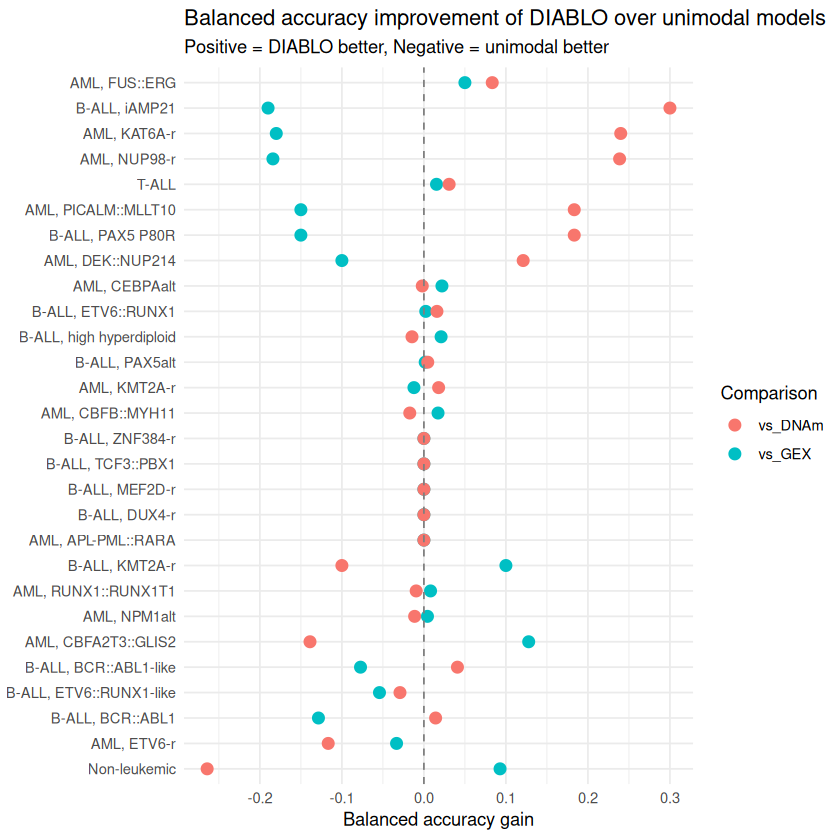

In [9]:

# ============================================================
# 2. Dot plot — improvement of DIABLO over unimodal
# ============================================================
improve_df <- data.frame(
  Class   = names(gex_ber),
  vs_GEX  = as.numeric(diablo_ber) - as.numeric(gex_ber),   # flipped vs before
  vs_DNAm = as.numeric(diablo_ber) - as.numeric(dnam_ber)
) |>
  pivot_longer(cols = c("vs_GEX","vs_DNAm"),
               names_to  = "Comparison",
               values_to = "BalAcc_improvement")

ggplot(improve_df, aes(x = BalAcc_improvement,
                       y = reorder(Class, BalAcc_improvement),
                       colour = Comparison)) +
  geom_point(size = 3) +
  geom_vline(xintercept = 0, linetype = "dashed", colour = "grey50") +
  labs(title    = "Balanced accuracy improvement of DIABLO over unimodal models",
       subtitle = "Positive = DIABLO better, Negative = unimodal better",
       x = "Balanced accuracy gain", y = NULL) +
  theme_minimal()


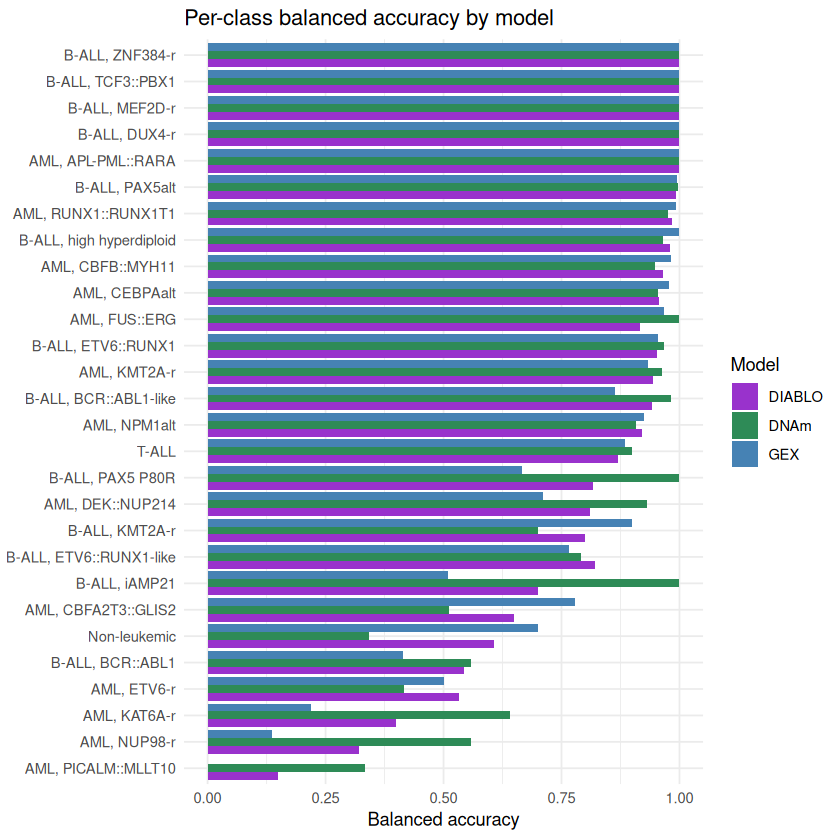

In [10]:

# ============================================================
# 3. Bar chart sorted by DIABLO balanced accuracy
# ============================================================
ggplot(bacc_long, aes(x = reorder(Class, BalAcc), y = BalAcc, fill = Model)) +
  geom_bar(stat = "identity", position = "dodge") +
  scale_fill_manual(values = c(GEX = "steelblue", DNAm = "seagreen", DIABLO = "darkorchid")) +
  coord_flip() +
  labs(title = "Per-class balanced accuracy by model", x = NULL, y = "Balanced accuracy") +
  theme_minimal()


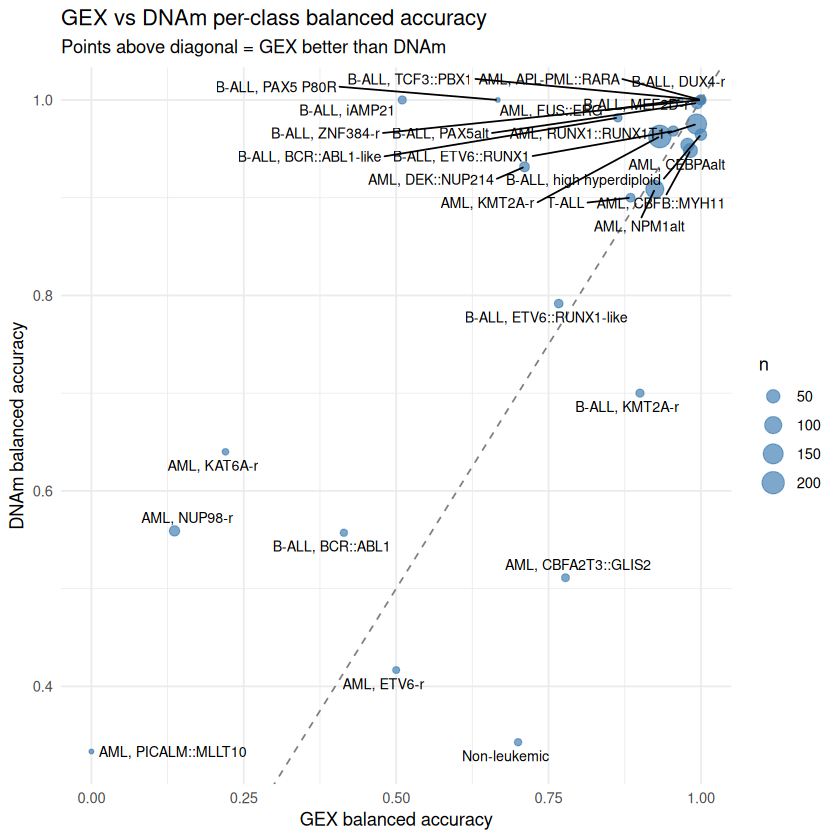

In [11]:

# ============================================================
# 4. Scatter — GEX vs DNAm balanced accuracy, sized by n
# ============================================================
class_sizes <- as.data.frame(table(Y_train))
colnames(class_sizes) <- c("Class", "n")

bacc_df <- left_join(bacc_df, class_sizes, by = "Class")

ggplot(bacc_df, aes(x = GEX, y = DNAm, size = n, label = Class)) +
  geom_point(alpha = 0.7, colour = "steelblue") +
  geom_abline(slope = 1, intercept = 0, linetype = "dashed", colour = "grey50") +
  ggrepel::geom_text_repel(size = 3, max.overlaps = 20) +
  labs(title    = "GEX vs DNAm per-class balanced accuracy",
       subtitle = "Points above diagonal = GEX better than DNAm",
       x = "GEX balanced accuracy", y = "DNAm balanced accuracy") +
  theme_minimal()

In [12]:
# ============================================================
# Overall summary
# ============================================================
overall <- data.frame(
  Model        = c("GEX", "DNAm", "DIABLO"),
  Mean_BalAcc  = round(c(mean(bacc_df$GEX),
                          mean(bacc_df$DNAm),
                          mean(bacc_df$DIABLO)), 3),
  Median_BalAcc = round(c(median(bacc_df$GEX),
                           median(bacc_df$DNAm),
                           median(bacc_df$DIABLO)), 3),
  Min_BalAcc   = round(c(min(bacc_df$GEX),
                          min(bacc_df$DNAm),
                          min(bacc_df$DIABLO)), 3),
  Max_BalAcc   = round(c(max(bacc_df$GEX),
                          max(bacc_df$DNAm),
                          max(bacc_df$DIABLO)), 3),
  Classes_above_0.5 = c(sum(bacc_df$GEX    > 0.5),
                         sum(bacc_df$DNAm   > 0.5),
                         sum(bacc_df$DIABLO > 0.5))
)
print(overall)

# ============================================================
# How many classes does DIABLO win/tie/lose vs each unimodal?
# ============================================================
cat("\n=== DIABLO vs GEX ===\n")
cat("DIABLO better: ", sum(bacc_df$DIABLO >  bacc_df$GEX),  "\n")
cat("Tied:          ", sum(bacc_df$DIABLO == bacc_df$GEX),  "\n")
cat("GEX better:    ", sum(bacc_df$DIABLO <  bacc_df$GEX),  "\n")

cat("\n=== DIABLO vs DNAm ===\n")
cat("DIABLO better: ", sum(bacc_df$DIABLO >  bacc_df$DNAm), "\n")
cat("Tied:          ", sum(bacc_df$DIABLO == bacc_df$DNAm), "\n")
cat("DNAm better:   ", sum(bacc_df$DIABLO <  bacc_df$DNAm), "\n")

# ============================================================
# Wilcoxon signed-rank test — is DIABLO significantly better?
# ============================================================
cat("\n=== Wilcoxon signed-rank test ===\n")
wt_gex  <- wilcox.test(bacc_df$DIABLO, bacc_df$GEX,
                        paired = TRUE, alternative = "greater")
wt_dnam <- wilcox.test(bacc_df$DIABLO, bacc_df$DNAm,
                        paired = TRUE, alternative = "greater")

cat("DIABLO vs GEX  p-value:", round(wt_gex$p.value,  4), "\n")
cat("DIABLO vs DNAm p-value:", round(wt_dnam$p.value, 4), "\n")

   Model Mean_BalAcc Median_BalAcc Min_BalAcc Max_BalAcc Classes_above_0.5
1    GEX       0.778         0.912      0.000          1                23
2   DNAm       0.834         0.958      0.333          1                25
3 DIABLO       0.806         0.918      0.150          1                25

=== DIABLO vs GEX ===
DIABLO better:  11 
Tied:           5 


GEX better:     12 

=== DIABLO vs DNAm ===
DIABLO better:  10 
Tied:           5 
DNAm better:    13 

=== Wilcoxon signed-rank test ===


Warning message in wilcox.test.default(bacc_df$DIABLO, bacc_df$GEX, paired = TRUE, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(bacc_df$DIABLO, bacc_df$GEX, paired = TRUE, :
“cannot compute exact p-value with zeroes”
Warning message in wilcox.test.default(bacc_df$DIABLO, bacc_df$DNAm, paired = TRUE, :
“cannot compute exact p-value with zeroes”


DIABLO vs GEX  p-value: 0.1119 
DIABLO vs DNAm p-value: 0.8792 


In [13]:
# Is DIABLO at least consistently competitive? (not worse)
wt_gex_two  <- wilcox.test(bacc_df$DIABLO, bacc_df$GEX,  paired = TRUE)
wt_dnam_two <- wilcox.test(bacc_df$DIABLO, bacc_df$DNAm, paired = TRUE)
cat("Two-sided DIABLO vs GEX  p-value:", round(wt_gex_two$p.value,  4), "\n")
cat("Two-sided DIABLO vs DNAm p-value:", round(wt_dnam_two$p.value, 4), "\n")

Warning message in wilcox.test.default(bacc_df$DIABLO, bacc_df$GEX, paired = TRUE):
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(bacc_df$DIABLO, bacc_df$GEX, paired = TRUE):
“cannot compute exact p-value with zeroes”
Warning message in wilcox.test.default(bacc_df$DIABLO, bacc_df$DNAm, paired = TRUE):
“cannot compute exact p-value with zeroes”


Two-sided DIABLO vs GEX  p-value: 0.2237 
Two-sided DIABLO vs DNAm p-value: 0.2541 


In [14]:
# Compare DNAm with GEX as well
wt_dnam_gex <- wilcox.test(bacc_df$DNAm, bacc_df$GEX, paired = TRUE)
cat("Two-sided DNAm vs GEX p-value:", round(wt_dnam_gex$p.value, 4), "\n")

Warning message in wilcox.test.default(bacc_df$DNAm, bacc_df$GEX, paired = TRUE):
“cannot compute exact p-value with zeroes”


Two-sided DNAm vs GEX p-value: 0.2541 


In [15]:
# For each class, take the better of GEX or DNAm
oracle_bacc <- pmax(bacc_df$GEX, bacc_df$DNAm)

oracle_summary <- data.frame(
  Model       = c("GEX", "DNAm", "DIABLO", "Oracle (best unimodal)"),
  Mean_BalAcc = round(c(mean(bacc_df$GEX),
                         mean(bacc_df$DNAm),
                         mean(bacc_df$DIABLO),
                         mean(oracle_bacc)), 3)
)
print(oracle_summary)

# Which modality wins per class?
bacc_df$Best_modality <- ifelse(bacc_df$GEX >= bacc_df$DNAm, "GEX", "DNAm")
print(bacc_df[, c("Class", "GEX", "DNAm", "Best_modality")])

                   Model Mean_BalAcc
1                    GEX       0.778
2                   DNAm       0.834
3                 DIABLO       0.806
4 Oracle (best unimodal)       0.871
                      Class       GEX      DNAm Best_modality
1        AML, APL-PML::RARA 1.0000000 1.0000000           GEX
2       AML, CBFA2T3::GLIS2 0.7777778 0.5111111           GEX
3          AML, CBFB::MYH11 0.9827586 0.9482759           GEX
4             AML, CEBPAalt 0.9780000 0.9540000           GEX
5          AML, DEK::NUP214 0.7105263 0.9315789          DNAm
6               AML, ETV6-r 0.5000000 0.4166667           GEX
7             AML, FUS::ERG 0.9666667 1.0000000          DNAm
8              AML, KAT6A-r 0.2200000 0.6400000          DNAm
9              AML, KMT2A-r 0.9325243 0.9626214          DNAm
10             AML, NPM1alt 0.9243478 0.9086957           GEX
11             AML, NUP98-r 0.1363636 0.5590909          DNAm
12      AML, PICALM::MLLT10 0.0000000 0.3333333          DNAm
13      A

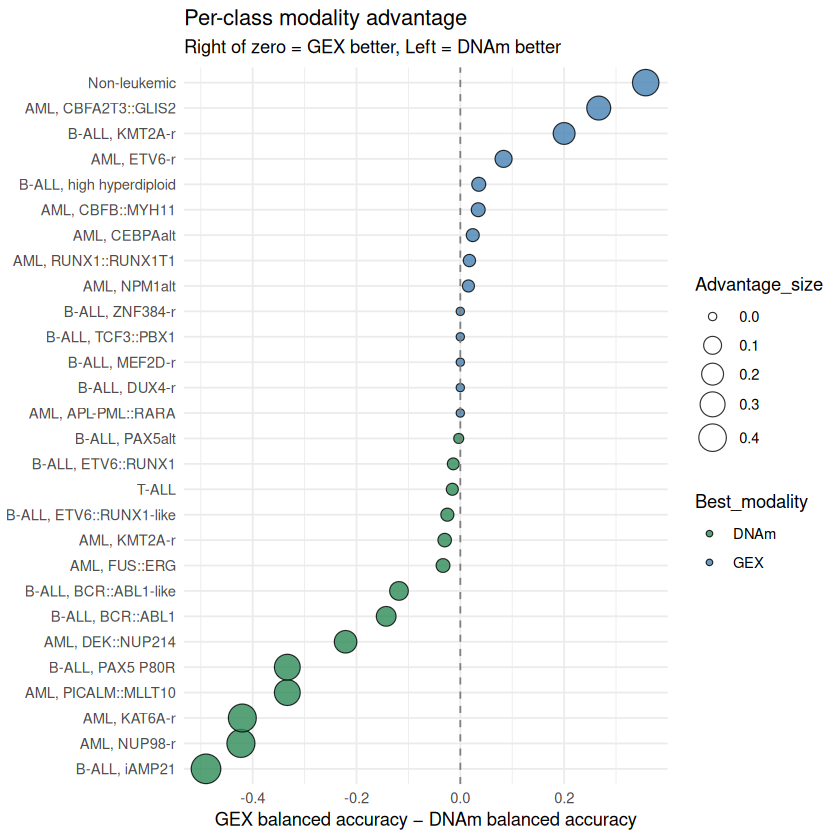

In [16]:
complement_df <- bacc_df |>
  mutate(
    GEX_advantage  = GEX  - DNAm,
    Best_modality  = ifelse(GEX >= DNAm, "GEX", "DNAm"),
    Advantage_size = abs(GEX - DNAm)
  ) |>
  arrange(GEX_advantage)

ggplot(complement_df,
       aes(x = GEX_advantage,
           y = reorder(Class, GEX_advantage),
           fill = Best_modality,
           size = Advantage_size)) +
  geom_point(shape = 21, alpha = 0.8) +
  geom_vline(xintercept = 0, linetype = "dashed", colour = "grey50") +
  scale_fill_manual(values = c(GEX = "steelblue", DNAm = "seagreen")) +
  scale_size_continuous(range = c(2, 8)) +
  labs(title    = "Per-class modality advantage",
       subtitle = "Right of zero = GEX better, Left = DNAm better",
       x = "GEX balanced accuracy − DNAm balanced accuracy",
       y = NULL) +
  theme_minimal()